# Discrete and smeared stringers: integrally stiffened Technion shells (Weller and Singer 1977; Poorveis and Kabir 2006)

How far is a model with discrete stringers from the smeared-stiffener theory
when the stringers are closely spaced? Weller and Singer [1] tested in axial
compression integrally stringer-stiffened shells of 7075-T6 aluminium alloy,
machined with the stringers outside, and give for each shell the
non-dimensional stringer properties, the buckling load of the linear
smeared-stiffener theory for two simple supports, SS3 ($w = M_x = N_x = v =
0$) and SS4 ($w = M_x = u = v = 0$), and the test load (Table 1, p. 723).
Poorveis and Kabir [2] analysed one of these shells (AS-27M2, their case A)
and a shell of Shen, Zhou and Chen (their case D, test from [3]) with a
geometrically nonlinear Ritz model, once with discrete and once with smeared
stringers (Table 2, p. 119). This notebook models the shells with discrete
stringers and compares with every one of these values:

- the smeared theory of Block, Card and Mikulas [4] (equation (15), simply
  supported SS3, membrane pre-buckling state), evaluated with the section
  properties of [1] (it reproduces the SS3 loads of [1]) and with the section
  of the discrete model, so that the **discreteness gap** (discrete model
  against smeared theory of the same section) is separated from the effect of
  the section;
- the tests of [1] and [3], and the smeared and discrete values of [2].

Weller and Singer selected the shells for general instability, except the
AS-27 series, whose Koiter parameter $\theta > 0.64$ was chosen on purpose to
study unstable postbuckling of the skin panels between the stringers (p.
722): for these shells Poorveis and Kabir found the discrete value 30 % below
the smeared one and attributed the difference to panel instability (p. 119).

[1] T. Weller and J. Singer, *Experimental studies on the buckling under
axial compression of integrally stringer-stiffened circular cylindrical
shells*, J. Appl. Mech. 44(4), 721-730, 1977, doi:10.1115/1.3424163.

[2] D. Poorveis and M. Z. Kabir, *Buckling of discretely stringer-stiffened
composite cylindrical shells under combined axial compression and external
pressure*, Scientia Iranica 13(2), 113-123, 2006.

[3] H.-S. Shen, P. Zhou and T.-Y. Chen, *Postbuckling analysis of stiffened
cylindrical shells under combined external pressure and axial compression*,
Thin-Walled Struct. 15, 43-63, 1993, doi:10.1016/0263-8231(93)90012-Y (cited
through [2]; not read).

[4] D. L. Block, M. F. Card and M. M. Mikulas, Jr., *Buckling of eccentrically
stiffened orthotropic cylinders*, NASA TN D-2960, 1965,
https://ntrs.nasa.gov/citations/19650021133.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from bfsccylinder.version import __version__ as bfsccylinder_version
from bfscplate2d.version import __version__ as bfscplate2d_version
from blade_cylinder_sector import (BladeCylinderSector, buckling_membrane,
                                   axial_nodes, normalize_phase, W)
from smeared_stiffened_cylinder import buckling_ss

print('bfsccylinder', bfsccylinder_version)
print('bfscplate2d', bfscplate2d_version)


def pct(value, ref):
    return 100*(value/ref - 1)


def table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    display(Markdown('\n'.join(out)))

bfsccylinder 0.7.1
bfscplate2d 0.5.0


## Shells, geometry and material

Table 1 of [1] (p. 723) gives, for each shell, the skin thickness $h$, $R/h$,
$L/R$, the eccentricity $e_1/h$ of the stringer centroid (printed as $-(e_1/h)$,
$e_1$ being negative outside, Fig. 1), the area parameter $A_1/(bh)$, the
moment of inertia of the stringer about its centroid $I_{11}/(bh^3)$, the
torsion parameter $\eta_{t1} = G_1 I_{t1}/(bD)$ with $D = E h^3/(12(1 -
\nu^2))$, Koiter's parameter $\theta = [12(1 - \nu^2)]^{1/4} (b/2\pi)
(Rh)^{-1/2}$ (nomenclature, p. 722), the SS3 and SS4 loads of the smeared
theory and the test load, in kg (kilogram-force). Material (p. 724): $E =
0.75 \times 10^4$ kg/mm$^2$; $\nu = 0.30$ (p. 722). The stringer spacing $b$
is not printed: it follows from $\theta$, and $2\pi R/b$ gives the number of
stringers $n_s$, an integer within the rounding of $\theta$.

The shells AS-26M1 to AS-26M3 are listed in Table 1 but excluded by the
authors from their summary because of irregular edge effects in the strain
records (footnote b); they are left out here too. For AS-35 the SS4 load is
printed as 460 kg, a misprint: the printed ratio $\rho_{SS4} = 0.610$ gives
$2850/0.610 = 4672$ kg (this value is not used below).

In [2]:
E = 0.75e4  # kg/mm^2, p. 724
nu = 0.30   # p. 722
KGF = 9.80665  # N
# Table 1 of [1], p. 723: h (mm), R/h, L/R, -(e1/h), A1/(bh), I11/(bh^3),
# eta_t1, theta, P_cr SS3, P_cr SS4, P_exp (kg)
TABLE1 = {
    'AS-27M1': (0.195, 618, 0.648, 3.86, 0.760, 2.860, 23.50, 0.807, 4190, 4540, 3600),
    'AS-27M2': (0.204, 591, 0.652, 3.67, 0.717, 2.400, 19.84, 0.789, 4210, 4600, 3300),
    'AS-27M3': (0.202, 597, 0.650, 3.72, 0.729, 2.520, 20.83, 0.793, 4240, 4610, 3920),
    'AS-34': (0.254, 472, 1.080, 2.97, 0.533, 1.080, 5.75, 0.470, 3430, 4750, 2800),
    'AS-35': (0.250, 480, 1.080, 3.04, 0.549, 1.180, 6.11, 0.474, 3390, None, 2850),
}
k4 = (12*(1 - nu**2))**0.25
D_E = 1/(12*(1 - nu**2))  # D/(E h^3)
G = E/(2*(1 + nu))
shells = {}
rows = []
for s, (h, Rh, LR, e, Ab, Ib, eta, theta, P3, P4, Pe) in TABLE1.items():
    R = Rh*h
    L = LR*R
    ns_real = 2*np.pi*R/(theta*2*np.pi*np.sqrt(R*h)/k4)
    ns = int(round(ns_real))
    b = 2*np.pi*R/ns
    A = Ab*b*h
    I = Ib*b*h**3
    J = eta*b*E*D_E*h**3/G
    shells[s] = dict(h=h, R=R, L=L, ns=ns, b=b, A=A, I=I, e=e*h, J=J,
                     P3=P3, P4=P4, Pe=Pe)
    rows.append([s, h, '%.2f' % R, '%.2f' % L, '%.2f (%d)' % (ns_real, ns),
                 '%.3f' % b, '%.4f' % A, '%.4f' % (e*h), '%.4f' % I,
                 '%.4f' % J, P3, P4 or '(4672)', Pe,
                 '%.3f' % (Pe/(2*np.pi*R)), '%.3f' % (Pe*KGF/(2*np.pi*R))])
table(['shell', 'h, mm', 'R, mm', 'L, mm', '2 pi R/b (n_s)', 'b, mm',
       'A_1, mm^2', 'e_1, mm', 'I_11, mm^4', 'I_t1, mm^4', 'SS3, kg',
       'SS4, kg', 'test, kg', 'test N, kg/mm', 'test N, N/mm'], rows)

| shell | h, mm | R, mm | L, mm | 2 pi R/b (n_s) | b, mm | A_1, mm^2 | e_1, mm | I_11, mm^4 | I_t1, mm^4 | SS3, kg | SS4, kg | test, kg | test N, kg/mm | test N, N/mm |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| AS-27M1 | 0.195 | 120.51 | 78.09 | 56.00 (56) | 13.521 | 2.0038 | 0.7527 | 0.2867 | 0.5610 | 4190 | 4540 | 3600 | 4.754 | 46.625 |
| AS-27M2 | 0.204 | 120.56 | 78.61 | 56.01 (56) | 13.527 | 1.9786 | 0.7487 | 0.2756 | 0.5425 | 4210 | 4600 | 3300 | 4.356 | 42.721 |
| AS-27M3 | 0.202 | 120.59 | 78.39 | 56.01 (56) | 13.531 | 1.9925 | 0.7514 | 0.2810 | 0.5531 | 4240 | 4610 | 3920 | 5.173 | 50.734 |
| AS-34 | 0.254 | 119.89 | 129.48 | 84.03 (84) | 8.968 | 1.2141 | 0.7544 | 0.1587 | 0.2012 | 3430 | 4750 | 2800 | 3.717 | 36.452 |
| AS-35 | 0.25 | 120.00 | 129.60 | 84.02 (84) | 8.976 | 1.2320 | 0.7600 | 0.1655 | 0.2040 | 3390 | (4672) | 2850 | 3.780 | 37.068 |

**Stringer section.** A rectangle of height $h_s$ and width $t_s$ standing on
the skin has $A_1 = t_s h_s$, $I_{11} = t_s h_s^3/12$ and $e_1 = (h +
h_s)/2$. With $h_s = \sqrt{12 I_{11}/A_1}$ the eccentricity of Table 1 is
reproduced to 0.2 % or better and the torsion constant $I_{t1}$ is that of a
rectangle (Saint-Venant, $\beta\, t_s^3 h_s$), within 1 %: the stringers of
[1] are rectangles, $t_s \times h_s$ (the cutters of [1] leave a curved
skin surface between the stringers, p. 724). The AS-27 stringers are wider
than they are tall.

In [3]:
def rect_J(a, c):
    # Saint-Venant torsion constant of a rectangle a x c
    a, c = max(a, c), min(a, c)
    return c**3*a*(1/3 - 64/np.pi**5*c/a*np.tanh(np.pi*a/(2*c)))


rows = []
for s, d in shells.items():
    d['hs'] = np.sqrt(12*d['I']/d['A'])
    d['ts'] = d['A']/d['hs']
    rows.append([s, '%.3f' % d['ts'], '%.3f' % d['hs'],
                 '%.4f (%+.2f %%)' % ((d['h'] + d['hs'])/2, pct((d['h'] + d['hs'])/2, d['e'])),
                 '%.4f (%+.1f %%)' % (rect_J(d['ts'], d['hs']), pct(rect_J(d['ts'], d['hs']), d['J']))])
table(['shell', 't_s, mm', 'h_s, mm', '(h + h_s)/2 vs e_1, mm', 'J of the rectangle vs I_t1, mm^4'], rows)

| shell | t_s, mm | h_s, mm | (h + h_s)/2 vs e_1, mm | J of the rectangle vs I_t1, mm^4 |
|---|---|---|---|---|
| AS-27M1 | 1.529 | 1.310 | 0.7527 (-0.00 %) | 0.5611 (+0.0 %) |
| AS-27M2 | 1.530 | 1.293 | 0.7485 (-0.03 %) | 0.5458 (+0.6 %) |
| AS-27M3 | 1.532 | 1.301 | 0.7515 (+0.01 %) | 0.5540 (+0.2 %) |
| AS-34 | 0.969 | 1.252 | 0.7532 (-0.15 %) | 0.2019 (+0.3 %) |
| AS-35 | 0.970 | 1.270 | 0.7598 (-0.02 %) | 0.2072 (+1.6 %) |

## Smeared-stiffener theory

Equation (15) of [4] (simply supported SS3, membrane pre-buckling state,
`smeared_stiffened_cylinder.buckling_ss`), minimized over $m = 1 \ldots 12$
and $n = 1 \ldots 60$, with the stringer properties of Table 1 reproduces the
SS3 loads of [1] within 0.1 %: the section and the material are read as
Weller and Singer read them.

The discrete model (below) represents each stringer by a plate strip normal
to the skin, from the middle surface of the skin to the tip of the stringer,
of thickness $t_s$ and width $H_s = h_s + h/2$. As a smeared section this
strip has $A = t_s H_s$, $\bar{z} = H_s/2$, $I_o = t_s H_s^3/3$ about the
middle surface of the skin (it overlaps the skin by $h/2$), and the
twisting stiffness of a Kirchhoff plate strip, $4 D_{66} H_s = G H_s t_s^3/3$,
which is 2 to 3 times $G I_{t1}$ of the rectangle for these squat stringers.
The twisting stiffness enters the general-instability load strongly (the
column "J = 0" shows how much), so the model is run twice: with the plate
strip as it is ("plate J") and with $D_{66}$ of the strip scaled so that $4
D_{66} H_s = G I_{t1}$ ("matched J", the main model). The discreteness gap
is the discrete model against equation (15) for the same strip.

In [4]:
mgrid = np.arange(1, 13)[:, None]
ngrid = np.arange(1, 61)[None, :]


def smeared(d, A, z, Io, J):
    N = buckling_ss(d['R'], d['L'], d['h'], E, nu, d['b'], A, z, Io, J, mgrid, ngrid)
    i, j = np.unravel_index(np.argmin(N), N.shape)
    return N[i, j], (int(mgrid[i, 0]), int(ngrid[0, j]))


rows = []
for s, d in shells.items():
    d['Hs'] = d['hs'] + d['h']/2
    d['Jplate'] = d['Hs']*d['ts']**3/3
    Ws = (d['A'], d['e'], d['I'] + d['A']*d['e']**2)
    Ps = (d['ts']*d['Hs'], d['Hs']/2, d['ts']*d['Hs']**3/3)
    d['sm_W'] = smeared(d, *Ws, d['J'])
    d['sm_W_J0'] = smeared(d, *Ws, 0.)
    d['sm_P_J'] = smeared(d, *Ps, d['J'])
    d['sm_P_Jp'] = smeared(d, *Ps, d['Jplate'])
    N3 = d['P3']/(2*np.pi*d['R'])
    rows.append([s, '%.3f' % N3,
                 '%.3f %s, %+.2f %%' % (d['sm_W'][0], d['sm_W'][1], pct(d['sm_W'][0], N3)),
                 '%.3f, %+.1f %%' % (d['sm_W_J0'][0], pct(d['sm_W_J0'][0], N3)),
                 '%.3f %s, %+.1f %%' % (d['sm_P_J'][0], d['sm_P_J'][1], pct(d['sm_P_J'][0], N3)),
                 '%.3f %s, %+.1f %%' % (d['sm_P_Jp'][0], d['sm_P_Jp'][1], pct(d['sm_P_Jp'][0], N3)),
                 '%.2f' % (d['J']/d['Jplate'])])
table(['shell', 'SS3 of [1], kg/mm', 'Eq. (15), section of [1]', 'same, J = 0',
       'Eq. (15), plate strip, matched J', 'Eq. (15), plate strip, plate J',
       'I_t1/J_plate'], rows)

| shell | SS3 of [1], kg/mm | Eq. (15), section of [1] | same, J = 0 | Eq. (15), plate strip, matched J | Eq. (15), plate strip, plate J | I_t1/J_plate |
|---|---|---|---|---|---|---|
| AS-27M1 | 5.534 | 5.540 (1, 13), +0.11 % | 3.859, -30.3 % | 5.555 (1, 13), +0.4 % | 7.998 (1, 11), +44.5 % | 0.33 |
| AS-27M2 | 5.558 | 5.557 (1, 13), -0.01 % | 3.965, -28.7 % | 5.574 (1, 13), +0.3 % | 8.037 (1, 11), +44.6 % | 0.33 |
| AS-27M3 | 5.596 | 5.589 (1, 13), -0.11 % | 3.959, -29.2 % | 5.607 (1, 13), +0.2 % | 8.068 (1, 11), +44.2 % | 0.33 |
| AS-34 | 4.553 | 4.547 (1, 11), -0.14 % | 4.002, -12.1 % | 4.582 (1, 11), +0.6 % | 5.171 (1, 11), +13.6 % | 0.48 |
| AS-35 | 4.496 | 4.491 (1, 11), -0.11 % | 3.940, -12.4 % | 4.527 (1, 11), +0.7 % | 5.122 (1, 11), +13.9 % | 0.48 |

## Model with discrete stringers

`BladeCylinderSector`: a sector of one stringer pitch with cyclic symmetry
(each harmonic $n$ solved separately; the harmonic $n$ contains the waves
$n + j n_s$ coupled by the stringers, and $n = n_s/2$ the local buckling of
the skin between the stringers with one half-wave per bay), the skin meshed
with `BFSCCylinderSanders` and the stringer with `BFSCPlate2D`, tied along
its root. Simply supported SS3 ends ($v = w = 0$ on the skin and the
stringer, $u$ free) and the membrane pre-buckling state of a uniform axial
strain (`buckling_membrane(model, 'SS', n)`), as in the smeared theory. The
lowest load over all harmonics $n = 1 \ldots n_s/2$ is the critical one.

In [5]:
def build(d, mesh, J='matched'):
    nx, nbay, nh = mesh
    model = BladeCylinderSector(R=d['R'], L=d['L'], h=d['h'], E=E, nu=nu,
                                rho=0., nstringers=d['ns'], nx=nx, nbay=nbay,
                                bs=d['ts'], Hs=d['Hs'], side='external', nh=nh)
    if J == 'matched':
        ABD = np.array(model.str_prop.ABD, dtype=float)
        ABD[5, 5] *= d['J']/d['Jplate']
        for plate in model.str_elements:
            plate.ABD = ABD
    return model


def scan(d, mesh, J='matched'):
    model = build(d, mesh, J)
    out = {}
    for n in range(1, d['ns']//2 + 1):
        N, X = buckling_membrane(model, 'SS', n, k=1)
        out[n] = (N[0], axial_nodes(model, X[:, 0]) + 1, X[:, 0])
    n = min(out, key=lambda n: out[n][0])
    return model, out, n

## Mesh convergence

Three meshes `(nx, nbay, nh)`: nodes along $x$, skin elements across the
stringer pitch, stringer elements along its height. The local modes of the
AS-27 shells have about nine axial half-waves and need the finer meshes.

In [6]:
MESHES = [(17, 8, 3), (25, 12, 4), (37, 16, 5)]
t0 = time.time()
rows = []
for s, d in shells.items():
    prev = None
    for mesh in MESHES:
        model, out, n = scan(d, mesh)
        N, m, _ = out[n]
        rows.append([s, mesh, model.Nr, '%.4f' % N, '(%d, %d)' % (m, n),
                     '' if prev is None else '%+.2f %%' % pct(N, prev)])
        prev = N
table(['shell', 'mesh', 'dofs per harmonic', 'N_cr, kg/mm', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| shell | mesh | dofs per harmonic | N_cr, kg/mm | (m, n) | change |
|---|---|---|---|---|---|
| AS-27M1 | (17, 8, 3) | 1904 | 4.1524 | (9, 28) |  |
| AS-27M1 | (25, 12, 4) | 4050 | 4.1376 | (9, 28) | -0.36 % |
| AS-27M1 | (37, 16, 5) | 7844 | 4.1342 | (9, 28) | -0.08 % |
| AS-27M2 | (17, 8, 3) | 1904 | 4.5601 | (9, 28) |  |
| AS-27M2 | (25, 12, 4) | 4050 | 4.5439 | (9, 28) | -0.35 % |
| AS-27M2 | (37, 16, 5) | 7844 | 4.5403 | (9, 28) | -0.08 % |
| AS-27M3 | (17, 8, 3) | 1904 | 4.4723 | (9, 28) |  |
| AS-27M3 | (25, 12, 4) | 4050 | 4.4564 | (9, 28) | -0.36 % |
| AS-27M3 | (37, 16, 5) | 7844 | 4.4528 | (9, 28) | -0.08 % |
| AS-34 | (17, 8, 3) | 1904 | 4.5452 | (1, 11) |  |
| AS-34 | (25, 12, 4) | 4050 | 4.5318 | (1, 11) | -0.30 % |
| AS-34 | (37, 16, 5) | 7844 | 4.5258 | (1, 11) | -0.13 % |
| AS-35 | (17, 8, 3) | 1904 | 4.4897 | (1, 11) |  |
| AS-35 | (25, 12, 4) | 4050 | 4.4763 | (1, 11) | -0.30 % |
| AS-35 | (37, 16, 5) | 7844 | 4.4703 | (1, 11) | -0.13 % |

1137 s


## Discrete against smeared stringers and the tests

The finest mesh, both twisting stiffnesses of the strip. $\bar{N} = P/(2\pi
R)$ in kg/mm (multiply by 9.807 for N/mm); "gap" is the discrete model
against equation (15) for the same strip and twisting stiffness.

In [7]:
t0 = time.time()
res = {}
for s, d in shells.items():
    for J in ('matched', 'plate'):
        res[(s, J)] = scan(d, MESHES[-1], J)
rows = []
for s, d in shells.items():
    N3, Ne = d['P3']/(2*np.pi*d['R']), d['Pe']/(2*np.pi*d['R'])
    for J, sm in (('matched', d['sm_P_J']), ('plate', d['sm_P_Jp'])):
        model, out, n = res[(s, J)]
        N, m, _ = out[n]
        rows.append([s, J, '%.3f (%d, %d)' % (N, m, n), '%.3f %s' % sm,
                     '**%+.1f %%**' % pct(N, sm[0]), '%.3f' % N3, '%+.1f %%' % pct(N, N3),
                     '%.3f' % Ne, '%+.1f %%' % pct(N, Ne)])
table(['shell', 'J', 'discrete N (m, n)', 'Eq. (15), same strip', 'gap',
       'SS3 of [1]', 'vs SS3', 'test', 'vs test'], rows)
print('%.0f s' % (time.time() - t0))

| shell | J | discrete N (m, n) | Eq. (15), same strip | gap | SS3 of [1] | vs SS3 | test | vs test |
|---|---|---|---|---|---|---|---|---|
| AS-27M1 | matched | 4.134 (9, 28) | 5.555 (1, 13) | **-25.6 %** | 5.534 | -25.3 % | 4.754 | -13.0 % |
| AS-27M1 | plate | 4.172 (9, 28) | 7.998 (1, 11) | **-47.8 %** | 5.534 | -24.6 % | 4.754 | -12.2 % |
| AS-27M2 | matched | 4.540 (9, 28) | 5.574 (1, 13) | **-18.5 %** | 5.558 | -18.3 % | 4.356 | +4.2 % |
| AS-27M2 | plate | 4.589 (9, 28) | 8.037 (1, 11) | **-42.9 %** | 5.558 | -17.4 % | 4.356 | +5.3 % |
| AS-27M3 | matched | 4.453 (9, 28) | 5.607 (1, 13) | **-20.6 %** | 5.596 | -20.4 % | 5.173 | -13.9 % |
| AS-27M3 | plate | 4.498 (9, 28) | 8.068 (1, 11) | **-44.2 %** | 5.596 | -19.6 % | 5.173 | -13.1 % |
| AS-34 | matched | 4.526 (1, 11) | 4.582 (1, 11) | **-1.2 %** | 4.553 | -0.6 % | 3.717 | +21.8 % |
| AS-34 | plate | 5.062 (1, 11) | 5.171 (1, 11) | **-2.1 %** | 4.553 | +11.2 % | 3.717 | +36.2 % |
| AS-35 | matched | 4.470 (1, 11) | 4.527 (1, 11) | **-1.2 %** | 4.496 | -0.6 % | 3.780 | +18.3 % |
| AS-35 | plate | 5.010 (1, 11) | 5.122 (1, 11) | **-2.2 %** | 4.496 | +11.4 % | 3.780 | +32.6 % |

1611 s


**Critical load of each harmonic.** The AS-27 shells buckle locally, in the
harmonic $n = n_s/2 = 28$ (one half-wave of the skin per bay); AS-34 and
AS-35 in a general mode with one axial half-wave.

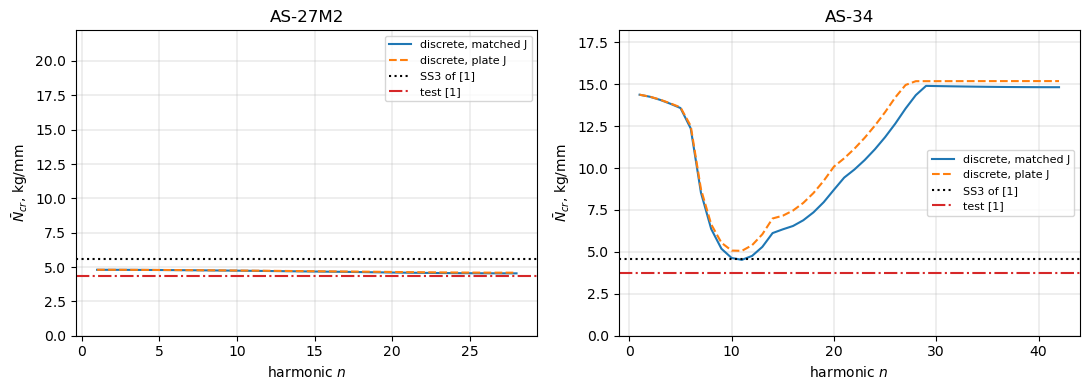

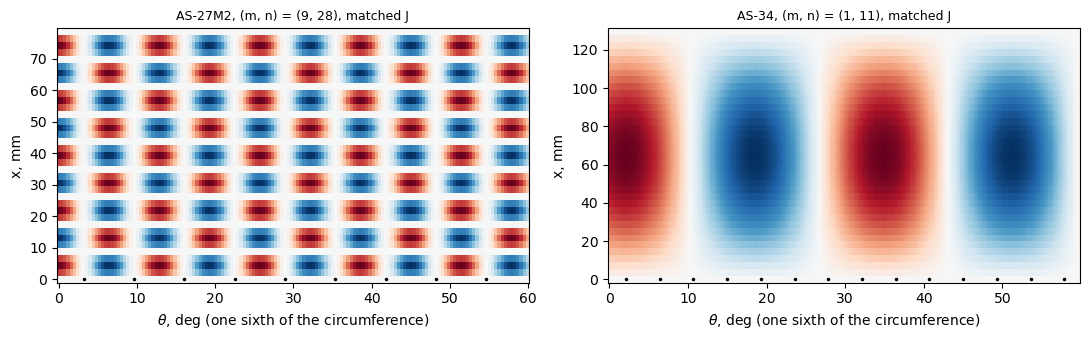

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, s in zip(axes, ('AS-27M2', 'AS-34')):
    d = shells[s]
    for J, style in (('matched', 'C0-'), ('plate', 'C1--')):
        out = res[(s, J)][1]
        ns = sorted(out)
        ax.plot(ns, [out[n][0] for n in ns], style, label='discrete, %s J' % J)
    ax.axhline(d['P3']/(2*np.pi*d['R']), color='k', ls=':', label='SS3 of [1]')
    ax.axhline(d['Pe']/(2*np.pi*d['R']), color='C3', ls='-.', label='test [1]')
    ax.set_ylim(0, 4*d['P3']/(2*np.pi*d['R']))
    ax.set_xlabel('harmonic $n$')
    ax.set_ylabel(r'$\bar{N}_{cr}$, kg/mm')
    ax.set_title(s)
    ax.grid(True, lw=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, s in zip(axes, ('AS-27M2', 'AS-34')):
    model, out, n = res[(s, 'matched')]
    w = normalize_phase(model.skin_field(out[n][2], W))
    th, wf = model.full_circumference(w, n)
    sel = th <= 2*np.pi/6
    ax.pcolormesh(np.degrees(th[sel]), model.xlin, wf[:, sel]/np.abs(wf).max(),
                  cmap='RdBu_r', vmin=-1, vmax=1, shading='auto')
    pos = (np.arange(model.nstringers) + 0.5)*model.phi
    pos = pos[pos <= 2*np.pi/6]
    ax.plot(np.degrees(pos), np.zeros_like(pos), 'k.', ms=3)
    ax.set_xlabel(r'$\theta$, deg (one sixth of the circumference)')
    ax.set_ylabel('x, mm')
    ax.set_title('%s, (m, n) = (%d, %d), matched J' % (s, out[n][1], n), fontsize=9)
plt.tight_layout()
plt.show()

## The cases of Poorveis and Kabir

Table 1 of [2] (p. 119) gives the shells of Table 2 with the same
non-dimensional parameters ($b$ here is the spacing $b_1 = 2\pi R/n_s$; $D$
that of the skin), $E = 7500$ kg/mm$^2$, $\nu = 0.3$, classical simple
supports, outside stringers. Case A is AS-27M2 of [1] (same $h$, $R$, $L$,
section; the test 4.356 kg/mm is 3300 kg of [1]); case B is cylinder 1 of
Card and Jones (1966), already modelled in the notebook
`card1966_stiffened_cylinder_buckling.ipynb` (its "test" value is the smeared
linear value of Card and Jones, footnote b of Table 2); case C is loaded by
external pressure (not modelled here); case D, with 85 stringers, is
modelled below. The values of [2] come from a geometrically nonlinear
analysis with pre-buckling deformations (Donnell kinematics, first-order
shear deformation of skin and stringers, Lagrange multipliers at the
interface), the stringer section from the same parameters.

In [9]:
# Table 1 of [2], p. 119: L, R, h (mm), n_s, A1/(b1 h), e1/h, I1/(b h^3), G1 J1/(b D)
POORVEIS_T1 = {'A': (78.618, 120.56, 0.204, 56, 0.717, 3.670, 2.400, 19.839),
               'D': (130.00, 120.10, 0.254, 85, 0.590, 3.420, 1.680, 6.563)}
# Table 2 of [2], p. 119 (kg/mm): test, smeared (nonlinear), discrete (nonlinear)
POORVEIS_T2 = {'A': (4.356, 6.110, 4.250), 'B': (20.43, 20.39, 21.45),
               'D': (5.334, 5.370, 5.450)}
d = {}
L, R, h, ns, Ab, e, Ib, eta = POORVEIS_T1['D']
b = 2*np.pi*R/ns
d = dict(h=h, R=R, L=L, ns=ns, b=b, A=Ab*b*h, I=Ib*b*h**3, e=e*h,
         J=eta*b*E*D_E*h**3/G)
d['hs'] = np.sqrt(12*d['I']/d['A'])
d['ts'] = d['A']/d['hs']
d['Hs'] = d['hs'] + h/2
d['Jplate'] = d['Hs']*d['ts']**3/3
print('case D: theta = %.3f, t_s = %.3f mm, h_s = %.3f mm, (h + h_s)/2 = %.4f mm (e_1 = %.4f mm), '
      'J of the rectangle %.4f mm^4 (I_t1 = %.4f)'
      % (k4*b/(2*np.pi*np.sqrt(R*h)), d['ts'], d['hs'], (h + d['hs'])/2, d['e'],
         rect_J(d['ts'], d['hs']), d['J']))
d['sm_W'] = smeared(d, d['A'], d['e'], d['I'] + d['A']*d['e']**2, d['J'])
Ps = (d['ts']*d['Hs'], d['Hs']/2, d['ts']*d['Hs']**3/3)
d['sm_P_J'] = smeared(d, *Ps, d['J'])
d['sm_P_Jp'] = smeared(d, *Ps, d['Jplate'])
shells['D'] = d
t0 = time.time()
rows = []
for mesh in [(25, 12, 4), (37, 16, 5)]:
    for J in ('matched', 'plate'):
        model, out, n = scan(d, mesh, J)
        res[('D', J)] = (model, out, n)
        rows.append([mesh, J, '%.3f (%d, %d)' % (out[n][0], out[n][1], n)])
table(['mesh', 'J', 'discrete N, kg/mm (m, n)'], rows)
print('%.0f s' % (time.time() - t0))

case D: theta = 0.465, t_s = 0.896 mm, h_s = 1.485 mm, (h + h_s)/2 = 0.8694 mm (e_1 = 0.8687 mm), J of the rectangle 0.2227 mm^4 (I_t1 = 0.2273)


| mesh | J | discrete N, kg/mm (m, n) |
|---|---|---|
| (25, 12, 4) | matched | 4.995 (1, 11) |
| (25, 12, 4) | plate | 5.390 (1, 11) |
| (37, 16, 5) | matched | 4.988 (1, 11) |
| (37, 16, 5) | plate | 5.384 (1, 11) |

578 s


In [10]:
rows = []
for case, s in (('A', 'AS-27M2'), ('D', 'D')):
    test, sm2, di2 = POORVEIS_T2[case]
    dd = shells[s]
    Nm = res[(s, 'matched')][1][res[(s, 'matched')][2]][0]
    Np = res[(s, 'plate')][1][res[(s, 'plate')][2]][0]
    rows.append([case, test, sm2, di2, '%+.1f %%' % pct(di2, sm2),
                 '%.3f' % dd['sm_W'][0], '%.3f (%+.1f %%)' % (dd['sm_P_J'][0], pct(Nm, dd['sm_P_J'][0])),
                 '%.3f' % Nm, '%+.1f %%' % pct(Nm, test), '%+.1f %%' % pct(Nm, di2), '%+.1f %%' % pct(Nm, sm2),
                 '%.3f' % Np])
table(['case', 'test', 'smeared [2]', 'discrete [2]', 'discrete vs smeared [2]',
       'Eq. (15), section of [2]', 'Eq. (15), strip, matched J (gap)', 'discrete, matched J',
       'vs test', 'vs discrete [2]', 'vs smeared [2]', 'discrete, plate J'], rows)

| case | test | smeared [2] | discrete [2] | discrete vs smeared [2] | Eq. (15), section of [2] | Eq. (15), strip, matched J (gap) | discrete, matched J | vs test | vs discrete [2] | vs smeared [2] | discrete, plate J |
|---|---|---|---|---|---|---|---|---|---|---|---|
| A | 4.356 | 6.11 | 4.25 | -30.4 % | 5.557 | 5.574 (-18.5 %) | 4.540 | +4.2 % | +6.8 % | -25.7 % | 4.589 |
| D | 5.334 | 5.37 | 5.45 | +1.5 % | 5.018 | 5.052 (-1.3 %) | 4.988 | -6.5 % | -8.5 % | -7.1 % | 5.384 |

**Case B** (`card1966_stiffened_cylinder_buckling.ipynb`, cylinder 1, SS,
membrane): this repository gives 1144 lb/in (20.43 kg/mm) with the section
of Card and Jones, where [2] reports 20.39 kg/mm smeared and 21.45 kg/mm
discrete (+5.2 %); 1 lb/in = 0.017858 kg/mm.

## Discussion

- **Input.** Equation (15) of [4] with the stringer properties of Table 1 of
  [1] reproduces the SS3 loads of [1] within 0.14 % for the five shells, so
  the section, the material and the number of stringers are read as Weller
  and Singer read them. The stringers are rectangles; their torsion constant
  $I_{t1}$ is that of the rectangle.
- **General instability (AS-34, AS-35, case D; $\theta = 0.47$, $b/\sqrt{Rh}
  = 1.6$).** The discrete model buckles in the general mode $(m, n) = (1,
  11)$ of the smeared theory, 1.2 % below equation (15) for the same
  plate strip with the matched twisting stiffness (2.1 to 2.2 % with the
  plate twisting stiffness). This is the discreteness gap at this spacing: one
  to two percent. Against the SS3 loads of [1] (for the rectangle) the
  discrete model is 0.6 % below; the overlap of the strip with the skin and its
  centroid at $H_s/2$ instead of $e_1$ make equation (15) for the strip 0.8 %
  higher than for the rectangle. The tests are at 82 and 84 % of SS3
  (the "linearity" of [1]), +18 and +22 % from the discrete model: the
  difference between test and theory is the imperfection sensitivity
  discussed in [1], not the discreteness of the stringers.
- **Panel instability (AS-27; $\theta = 0.79$ to 0.81).** The lowest mode of
  the discrete model is local: the skin between the stringers buckles with
  one half-wave per bay ($n = n_s/2 = 28$) and nine axial half-waves, at
  4.13 to 4.54 kg/mm, 18.5 to 25.6 % below the general instability of the smeared
  theory, which cannot represent this mode. This is the case of a large
  "gap" in the literature: Poorveis and Kabir found their discrete value 30 %
  below their smeared one for AS-27M2 and attributed it to panel instability
  ([2], p. 119). The discrete model of this notebook is +4.2 % from the
  test of AS-27M2 and +6.8 % from the discrete value of [2] (whose model
  includes the nonlinear pre-buckling deformation and transverse shear); the
  three tests of the nearly equal AS-27 shells scatter from 4.36 to 5.17
  kg/mm, and the model is -13.0, +4.2 and -13.9 % from them. The local load is almost
  independent of the twisting stiffness of the stringers (+0.9 to +1.1 % from
  matched to plate $J$), whereas the general-instability load of the smeared
  theory rises by 44 % with the plate twisting stiffness: with an unmatched
  plate strip the apparent gap would be 43 to 48 %. In the model the skin
  bay is the whole pitch $b = 13.5$ mm, the stringer root being a line; the
  real stringers are 1.53 mm wide (11 % of the pitch), which leaves a
  narrower skin panel and would raise the local load (a plate-buckling load
  scales with the inverse square of the panel width: $(13.53/12.0)^2 = 1.27$
  for the free width, an estimate, not a computed value).
- **Case D of [2]** (85 stringers, from Shen, Zhou and Chen [3]): discrete
  4.988 kg/mm, -1.3 % from equation (15) for the same strip, -6.5 %
  from the test of [3] cited by [2]. Poorveis and Kabir give the discrete
  value 1.5 % *above* the smeared one (5.450 and 5.370 kg/mm); their smeared
  nonlinear value is 7 % above equation (15) with their own section (5.018
  kg/mm), so the difference between their two models and the linear theory
  is larger than the discreteness effect found here. Case B of [2] (cylinder
  1 of Card and Jones, discrete 5.2 % above smeared in [2]): both
  implementations of the card1966 notebooks give the discrete simply
  supported membrane load within 0.1 % of the smeared $\bar{N}_s$.
- **Summary of the gap.** With closely spaced stringers that buckle in a
  general mode, the discrete model is 1 to 2 % below the smeared theory of
  the same section; when the skin between the stringers is prone to panel
  buckling ($\theta > 0.64$), the discrete model buckles locally, 19 to 26 %
  below the smeared general instability. Weller and Singer write that the
  discreteness "has also been studied and found to be negligible for closely
  spaced stiffened cylinders except for unusual geometries" (p. 722); the
  AS-27 shells are such a geometry by design.
- **The panels implementation of this case**
  (`panels/notebooks/weller1977_blade_cylinder_buckling.ipynb`: half cylinder
  of curved Sanders skin panels and `plate_clpt_gl` blades, the same strips,
  matched and plate $J$, 20 x 10 x 5 terms) gives the same modes and agrees
  within 0.7 %: AS-27M1/M2/M3 4.131, 4.536, 4.449 kg/mm (here 4.134, 4.540,
  4.453); AS-34 and AS-35 4.504 and 4.448 (here 4.526 and 4.470); case D
  4.957 (whole cylinder; here 4.988). Its gaps are -1.7 % (AS-34, AS-35) and
  -1.9 % (case D) with the matched $J$, -18.6 to -25.6 % for the AS-27 shells.